# Этап 1. Создание проекта и установка библиотек

In [1]:
# ПРОЕКТ:
# Система обнаружения дефектов
# на поверхности металлического изделия

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import time

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

OpenCV: 5.0.0
NumPy: 2.1.3
Pandas: 2.2.3


# Этап 2. Загрузка изображения

In [2]:

# ЗАГРУЗКА ИЗОБРАЖЕНИЯ

from google.colab import files

uploaded = files.upload()

# Получаем имя загруженного файла
image_name = list(uploaded.keys())[0]

# Загружаем изображение
image = cv2.imread(image_name)

# Проверяем, удалось ли загрузить изображение
if image is None:
    raise ValueError("Не удалось загрузить изображение!")

# OpenCV загружает изображение в формате BGR,
# поэтому переводим его в RGB для Matplotlib
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Файл:", image_name)
print("Размер изображения:", image.shape)
print("Высота:", image.shape[0])
print("Ширина:", image.shape[1])

Saving WhatsApp Image 2026-10-11 at 22.58.09.jpeg to WhatsApp Image 2026-10-11 at 22.58.09.jpeg
Файл: WhatsApp Image 2026-10-11 at 22.58.09.jpeg
Размер изображения: (534, 533, 3)
Высота: 534
Ширина: 533


# Этап 3. Просмотр исходного изображения

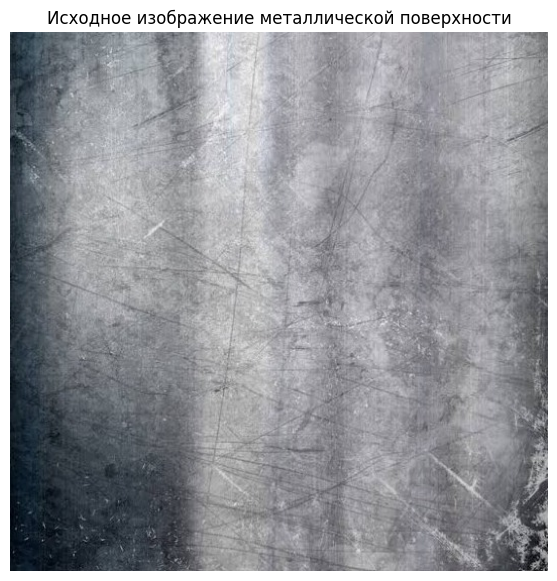

In [3]:
# ПРОСМОТР ИСХОДНОГО ИЗОБРАЖЕНИЯ

plt.figure(figsize=(12, 7))

plt.imshow(image_rgb)
plt.title("Исходное изображение металлической поверхности")
plt.axis("off")

plt.show()

# Этап 4. Перевод в оттенки серого

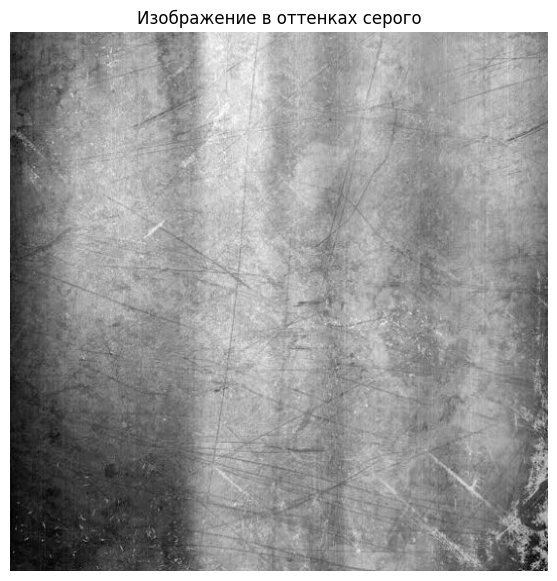

In [4]:
# ПРЕОБРАЗОВАНИЕ В ОТТЕНКИ СЕРОГО

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 7))

plt.imshow(gray, cmap="gray")
plt.title("Изображение в оттенках серого")
plt.axis("off")

plt.show()

# Этап 5. Gaussian Blur — удаление шума

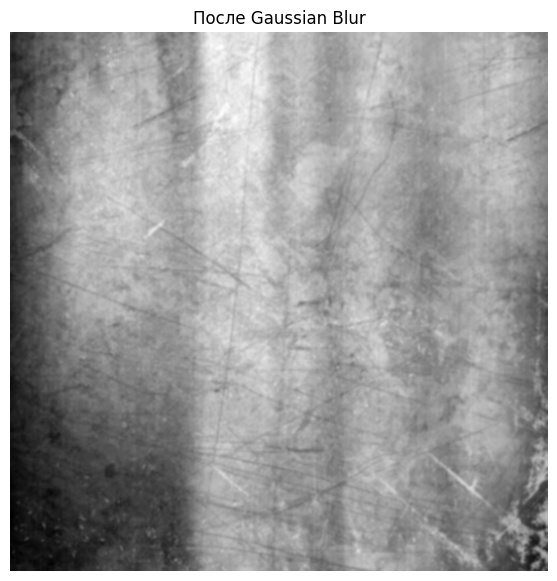

In [5]:
# GAUSSIAN BLUR
# Удаление мелкого шума

blur = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

plt.figure(figsize=(12, 7))

plt.imshow(blur, cmap="gray")
plt.title("После Gaussian Blur")
plt.axis("off")

plt.show()

Gaussian Blur немного сглаживает изображение.

Это необходимо потому, что Canny и thresholding могут реагировать не только на настоящие дефекты, но и на:

*   мелкий шум;
*   царапины;
*   текстуру металла;
*   отдельные пиксели;
*   небольшие изменения освещения.


# Этап 6. Улучшение контраста с помощью CLAHE

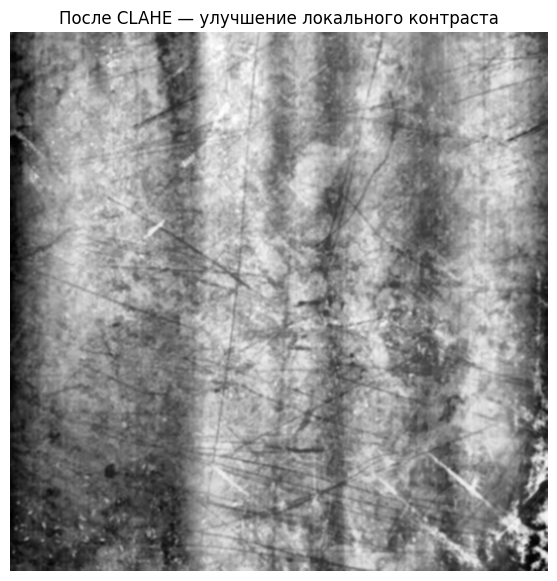

In [6]:
# CLAHE
# Локальное улучшение контраста

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(blur)

plt.figure(figsize=(12, 7))

plt.imshow(enhanced, cmap="gray")
plt.title("После CLAHE — улучшение локального контраста")
plt.axis("off")

plt.show()

На металлической поверхности освещение может быть неоднородным.

# Этап 7. Обнаружение трещин с помощью Canny

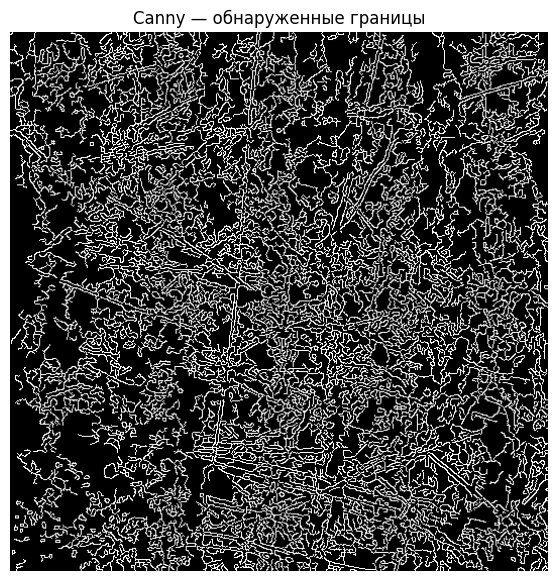

In [7]:
# CANNY EDGE DETECTION
# Обнаружение границ и тонких дефектов

edges = cv2.Canny(
    enhanced,
    threshold1=50,
    threshold2=150
)

plt.figure(figsize=(12, 7))

plt.imshow(edges, cmap="gray")
plt.title("Canny — обнаруженные границы")
plt.axis("off")

plt.show()

Canny ищет резкие изменения яркости.

На изображении edges границы становятся белыми, а остальная часть — чёрной.
Это особенно полезно для тонких линейных трещин.

# Этап 8. Морфологическое закрытие трещин

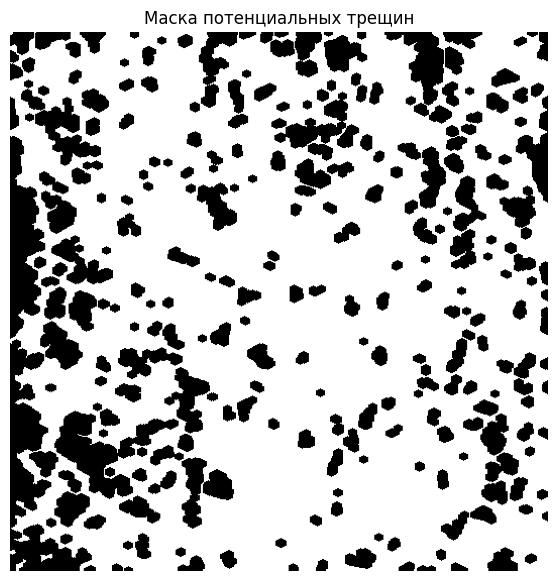

In [8]:
# МОРФОЛОГИЧЕСКОЕ ЗАКРЫТИЕ

kernel_crack = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (5, 5)
)

crack_mask = cv2.morphologyEx(
    edges,
    cv2.MORPH_CLOSE,
    kernel_crack,
    iterations=2
)

plt.figure(figsize=(12, 7))

plt.imshow(crack_mask, cmap="gray")
plt.title("Маска потенциальных трещин")
plt.axis("off")

plt.show()

# Этап 9. Обнаружение пятен

Для пятен используем другой подход — бинарную сегментацию.

Сначала попробуем автоматический порог Otsu.

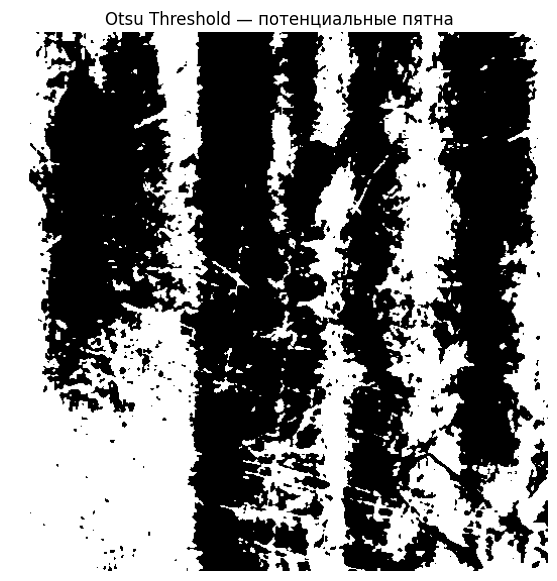

Автоматически выбранный порог: 133.0


In [9]:
# OTSU THRESHOLDING
# Сегментация потенциальных пятен

_, stain_mask = cv2.threshold(
    enhanced,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

plt.figure(figsize=(12, 7))

plt.imshow(stain_mask, cmap="gray")
plt.title("Otsu Threshold — потенциальные пятна")
plt.axis("off")

plt.show()

print("Автоматически выбранный порог:", _)

cv2.THRESH_OTSU

самостоятельно выбирает порог.

# Этап 10. Очистка маски пятен

После thresholding могут появиться маленькие шумовые области.

Поэтому применяем морфологическую обработку.

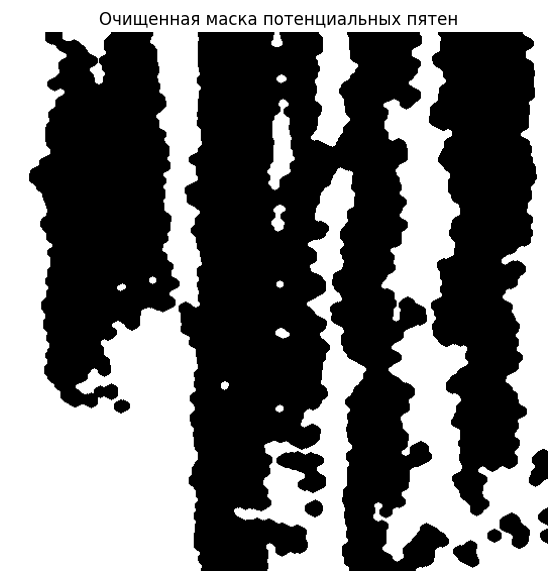

In [10]:
# МОРФОЛОГИЧЕСКАЯ ОЧИСТКА МАСКИ ПЯТЕН

kernel_stain = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (7, 7)
)

stain_mask_clean = cv2.morphologyEx(
    stain_mask,
    cv2.MORPH_OPEN,
    kernel_stain,
    iterations=1
)

stain_mask_clean = cv2.morphologyEx(
    stain_mask_clean,
    cv2.MORPH_CLOSE,
    kernel_stain,
    iterations=2
)

plt.figure(figsize=(12, 7))

plt.imshow(stain_mask_clean, cmap="gray")
plt.title("Очищенная маска потенциальных пятен")
plt.axis("off")

plt.show()

Здесь мы использовали две операции:

**Opening**

Удаляет маленькие шумовые объекты.

**Closing**

Заполняет небольшие разрывы внутри объектов.

# Этап 11. Поиск контуров

In [11]:
# ПОИСК КОНТУРОВ

# Контуры потенциальных трещин
contours_crack, _ = cv2.findContours(
    crack_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Контуры потенциальных пятен
contours_stain, _ = cv2.findContours(
    stain_mask_clean,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Найдено контуров трещин:", len(contours_crack))
print("Найдено контуров пятен:", len(contours_stain))

Найдено контуров трещин: 7
Найдено контуров пятен: 15


# Этап 12. Фильтрация маленьких объектов

In [12]:
# ЭТАП 12. УЛУЧШЕННАЯ ФИЛЬТРАЦИЯ КОНТУРОВ

image_h, image_w = gray.shape
image_area = image_h * image_w

def filter_contours_by_area(
    contours,
    min_area=30,
    max_area_ratio=0.10,
    reject_border=True
):
    """
    Фильтрует контуры по площади.

    min_area:
        минимальная площадь в пикселях.

    max_area_ratio:
        максимальная допустимая доля площади
        изображения для одного контура.

    reject_border:
        исключает контуры, касающиеся границы
        изображения.
    """

    filtered = []

    for contour in contours:
        area = cv2.contourArea(contour)

        # Слишком маленький объект
        if area < min_area:
            continue

        # Слишком большая область
        if area > image_area * max_area_ratio:
            continue

        x, y, w, h = cv2.boundingRect(contour)

        # Исключаем контуры, касающиеся края
        if reject_border:
            touches_border = (
                x <= 0 or
                y <= 0 or
                x + w >= image_w or
                y + h >= image_h
            )

            if touches_border:
                continue

        filtered.append(contour)

    return filtered


# Фильтрация потенциальных трещин
filtered_crack_contours = filter_contours_by_area(
    contours_crack,
    min_area=10,
    max_area_ratio=0.03,
    reject_border=True
)

# Фильтрация потенциальных пятен
filtered_stain_contours = filter_contours_by_area(
    contours_stain,
    min_area=100,
    max_area_ratio=0.10,
    reject_border=True
)

print("Трещиноподобных областей:", len(filtered_crack_contours))
print("Пятноподобных областей:", len(filtered_stain_contours))


Трещиноподобных областей: 1
Пятноподобных областей: 2


# Этап 13. Финальная визуализация

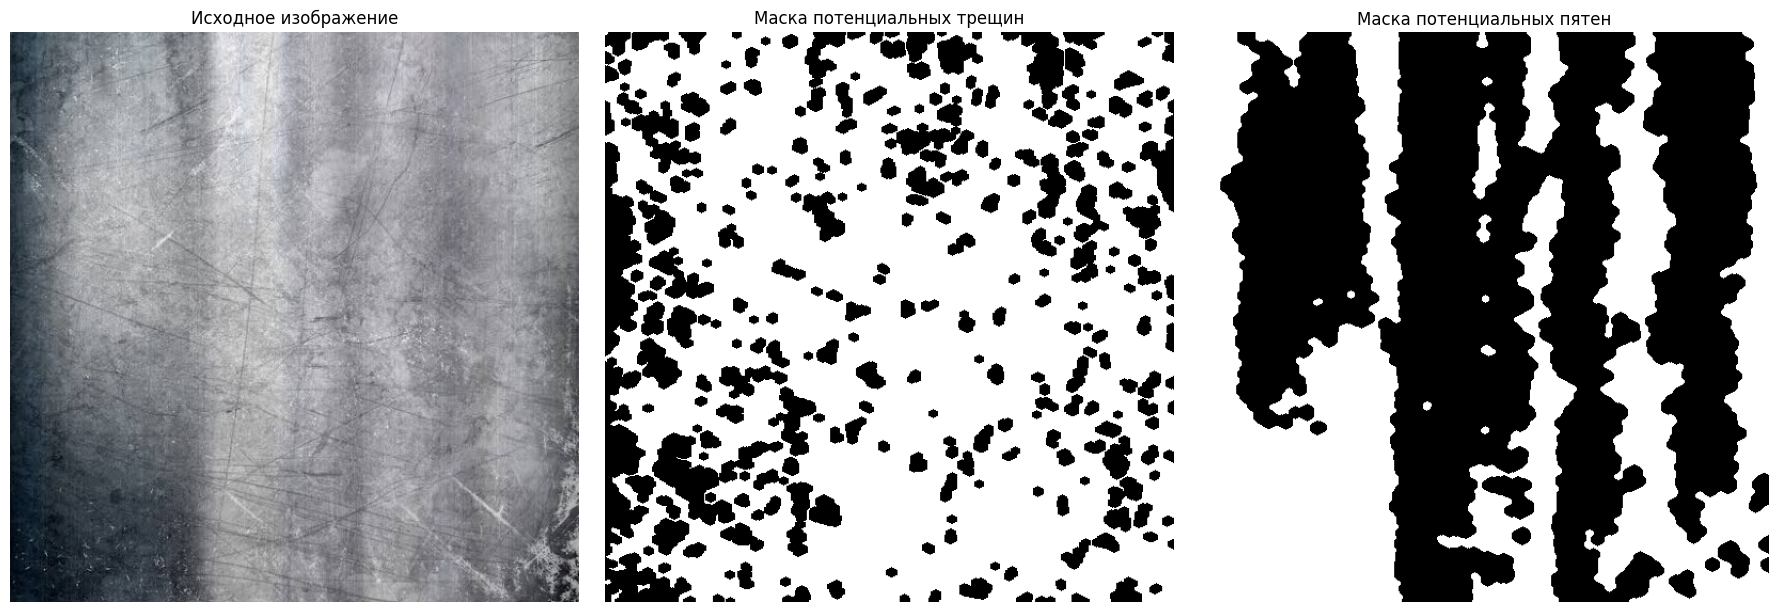

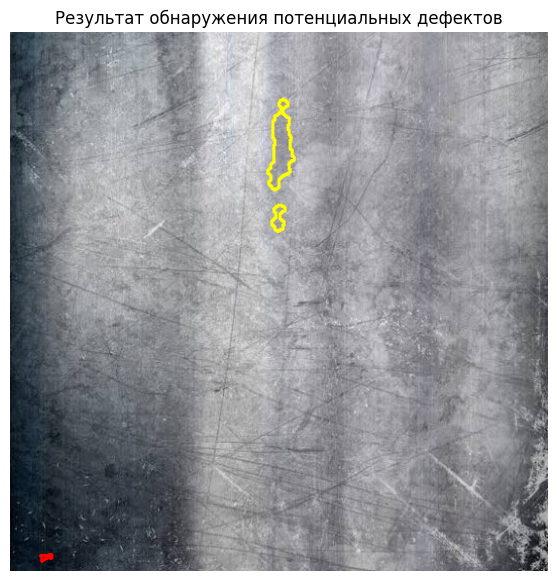

In [14]:
#ФИНАЛЬНАЯ ВИЗУАЛИЗАЦИЯ

result = image_rgb.copy()

# Потенциальные трещины — красный цвет
cv2.drawContours(
    result,
    filtered_crack_contours,
    -1,
    (255, 0, 0),
    2
)

# Потенциальные пятна — жёлтый цвет
cv2.drawContours(
    result,
    filtered_stain_contours,
    -1,
    (255, 255, 0),
    2
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image_rgb)
axes[0].set_title("Исходное изображение")

axes[1].imshow(crack_mask, cmap="gray")
axes[1].set_title("Маска потенциальных трещин")

axes[2].imshow(stain_mask_clean, cmap="gray")
axes[2].set_title("Маска потенциальных пятен")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 7))
plt.imshow(result)
plt.title("Результат обнаружения потенциальных дефектов")
plt.axis("off")
plt.show()


Здесь:

*   **красные контуры** — потенциальные трещины;
*   **жёлтые контуры** — потенциальные пятна.

# Этап 14. Добавим подписи

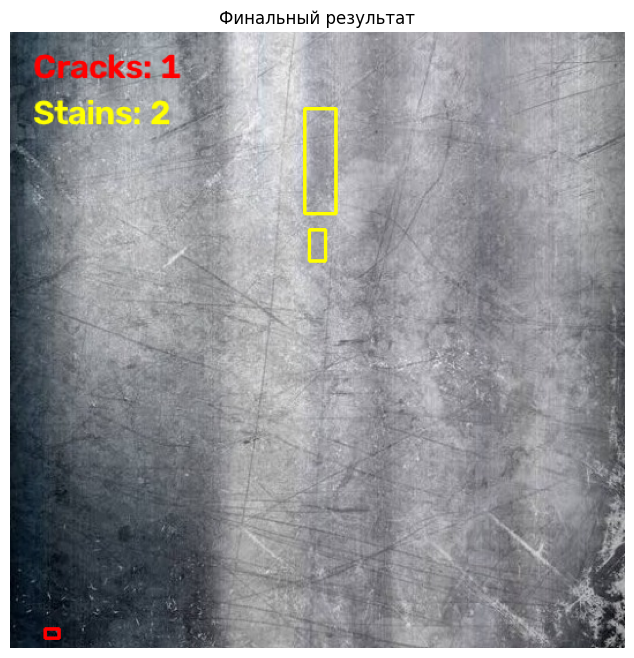

In [15]:
# ПОДПИСИ ДЕФЕКТОВ

result_labeled = image_rgb.copy()

crack_count = 0
stain_count = 0

# Трещины
for contour in filtered_crack_contours:

    area = cv2.contourArea(contour)

    if area < 30:
        continue

    x, y, w, h = cv2.boundingRect(contour)

    cv2.rectangle(
        result_labeled,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        2
    )

    crack_count += 1

# Пятна
for contour in filtered_stain_contours:

    area = cv2.contourArea(contour)

    if area < 100:
        continue

    x, y, w, h = cv2.boundingRect(contour)

    cv2.rectangle(
        result_labeled,
        (x, y),
        (x + w, y + h),
        (255, 255, 0),
        2
    )

    stain_count += 1

# Выводим информацию на изображение
cv2.putText(
    result_labeled,
    f"Cracks: {crack_count}",
    (20, 40),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (255, 0, 0),
    2
)

cv2.putText(
    result_labeled,
    f"Stains: {stain_count}",
    (20, 80),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (255, 255, 0),
    2
)

plt.figure(figsize=(14, 8))

plt.imshow(result_labeled)
plt.title("Финальный результат")
plt.axis("off")

plt.show()

# Этап 15. Таблица обнаруженных дефектов

In [16]:
# ТАБЛИЦА ОБНАРУЖЕННЫХ ДЕФЕКТОВ

defects = []

# Информация о трещинах
for i, contour in enumerate(filtered_crack_contours, start=1):

    area = cv2.contourArea(contour)
    x, y, w, h = cv2.boundingRect(contour)

    defects.append({
        "ID": i,
        "Тип": "Трещина",
        "Площадь": round(area, 2),
        "X": x,
        "Y": y,
        "Ширина": w,
        "Высота": h
    })

# Информация о пятнах
start_id = len(defects) + 1

for i, contour in enumerate(filtered_stain_contours, start=start_id):

    area = cv2.contourArea(contour)
    x, y, w, h = cv2.boundingRect(contour)

    defects.append({
        "ID": i,
        "Тип": "Пятно",
        "Площадь": round(area, 2),
        "X": x,
        "Y": y,
        "Ширина": w,
        "Высота": h
    })

df_defects = pd.DataFrame(defects)

df_defects

,ID,Тип,Площадь,X,Y,Ширина,Высота
0,1,Трещина,33.0,30,517,12,8
1,2,Пятно,196.0,259,171,14,27
2,3,Пятно,1201.5,255,66,27,91


In [ ]:
import cv2
import pandas as pd

# Размеры исходного изображения
image_h, image_w = gray.shape
image_area = image_h * image_w

def describe_contours(contours, defect_type):
    results = []

    for i, contour in enumerate(contours, start=1):
        # Площадь объекта
        area = cv2.contourArea(contour)

        # Координаты и размеры ограничивающего прямоугольника
        x, y, w, h = cv2.boundingRect(contour)

        # Отношение сторон
        aspect_ratio = w / h if h != 0 else 0

        # Доля площади изображения в процентах
        area_percentage = area / image_area * 100

        results.append({
            "Тип дефекта": defect_type,
            "№ объекта": i,
            "Площадь контура (пикс.)": round(area, 2),
            "X": x,
            "Y": y,
            "Ширина": w,
            "Высота": h,
            "Отношение сторон": round(aspect_ratio, 2),
            "Доля изображения (%)": round(area_percentage, 4)
        })

    return results


# Анализ обнаруженных трещин и пятен
crack_results = describe_contours(
    filtered_crack_contours, "Трещина"
)

stain_results = describe_contours(
    filtered_stain_contours, "Пятно"
)

# Объединяем результаты в одну таблицу
all_results = crack_results + stain_results
defects_df = pd.DataFrame(all_results)

if not defects_df.empty:
    display(defects_df)
else:
    print("Дефекты не обнаружены.")

print("Количество обнаруженных трещин:",
      len(filtered_crack_contours))

print("Количество обнаруженных пятен:",
      len(filtered_stain_contours))


,Тип дефекта,№ объекта,Площадь контура (пикс.),X,Y,Ширина,Высота,Отношение сторон,Доля изображения (%)
0,Трещина,1,33.0,30,517,12,8,1.50,0.0116
1,Пятно,1,196.0,259,171,14,27,0.52,0.0689
2,Пятно,2,1201.5,255,66,27,91,0.30,0.4221


Количество обнаруженных трещин: 1
Количество обнаруженных пятен: 2


# Этап 16. Общая площадь дефектов

In [18]:
#ПЛОЩАДЬ ОБЪЕДИНЁННОЙ МАСКИ

image_area = gray.shape[0] * gray.shape[1]

crack_mask_final = np.zeros(gray.shape, dtype=np.uint8)
stain_mask_final = np.zeros(gray.shape, dtype=np.uint8)

cv2.drawContours(
    crack_mask_final,
    filtered_crack_contours,
    -1, 255, cv2.FILLED
)

cv2.drawContours(
    stain_mask_final,
    filtered_stain_contours,
    -1, 255, cv2.FILLED
)

combined_mask = cv2.bitwise_or(
    crack_mask_final,
    stain_mask_final
)

defect_pixels = cv2.countNonZero(combined_mask)
defect_percentage = defect_pixels / image_area * 100

print(f"Площадь изображения: {image_area} пикс.")
print(f"Площадь маски дефектов: {defect_pixels} пикс.")
print(f"Доля маски: {defect_percentage:.2f}%")
print(f"Трещиноподобных областей: {len(filtered_crack_contours)}")
print(f"Пятноподобных областей: {len(filtered_stain_contours)}")

assert 0 <= defect_percentage <= 100


Площадь изображения: 284622 пикс.
Площадь маски дефектов: 1574 пикс.
Доля маски: 0.55%
Трещиноподобных областей: 1
Пятноподобных областей: 2


# Этап 17. Измерение времени обработки

In [20]:

#ВРЕМЯ ОБРАБОТКИ

start_time = time.perf_counter()

# Повторяем основные вычисления
gray_test = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

blur_test = cv2.GaussianBlur(
    gray_test, (5, 5), 0
)

enhanced_test = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
).apply(blur_test)

edges_test = cv2.Canny(
    enhanced_test, 50, 150
)

crack_test = cv2.morphologyEx(
    edges_test,
    cv2.MORPH_CLOSE,
    cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (5, 5)
    ),
    iterations=2
)

_, stain_test = cv2.threshold(
    enhanced_test,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

stain_test = cv2.morphologyEx(
    stain_test,
    cv2.MORPH_OPEN,
    cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (7, 7)
    )
)

end_time = time.perf_counter()

print(
    f"Время предварительной обработки и сегментации: "
    f"{end_time - start_time:.5f} секунд"
)


Время предварительной обработки и сегментации: 0.04959 секунд


# Этап 18. Тестирование на разных изображениях

In [21]:

#ТЕСТИРОВАНИЕ НА НЕСКОЛЬКИХ ФОТО

from google.colab import files

test_files = files.upload()

test_results = []

for filename, file_bytes in test_files.items():

    # Декодируем загруженное изображение
    arr = np.frombuffer(file_bytes, dtype=np.uint8)
    img = cv2.imdecode(arr, cv2.IMREAD_COLOR)

    if img is None:
        print("Не удалось прочитать:", filename)
        continue

    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    blur_img = cv2.GaussianBlur(
        gray_img, (5, 5), 0
    )

    clahe_obj = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced_img = clahe_obj.apply(blur_img)

    # Потенциальные трещины
    edges_img = cv2.Canny(
        enhanced_img, 50, 150
    )

    crack_img = cv2.morphologyEx(
        edges_img,
        cv2.MORPH_CLOSE,
        cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (5, 5)
        ),
        iterations=2
    )

    # Потенциальные пятна
    _, stain_img = cv2.threshold(
        enhanced_img,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    stain_img = cv2.morphologyEx(
        stain_img,
        cv2.MORPH_OPEN,
        cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (7, 7)
        )
    )

    # Контуры
    cc, _ = cv2.findContours(
        crack_img,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cs, _ = cv2.findContours(
        stain_img,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    h, w = gray_img.shape
    total_pixels = h * w

    # Применяем ту же фильтрацию, что и в основном проекте
    cc_filtered = filter_contours_by_area(
        cc, min_area=10,
        max_area_ratio=0.03,
        reject_border=True
    )

    cs_filtered = filter_contours_by_area(
        cs, min_area=100,
        max_area_ratio=0.10,
        reject_border=True
    )

    # Объединённая маска
    mask_c = np.zeros((h, w), dtype=np.uint8)
    mask_s = np.zeros((h, w), dtype=np.uint8)

    cv2.drawContours(
        mask_c, cc_filtered, -1,
        255, cv2.FILLED
    )

    cv2.drawContours(
        mask_s, cs_filtered, -1,
        255, cv2.FILLED
    )

    mask_all = cv2.bitwise_or(mask_c, mask_s)

    test_results.append({
        "Изображение": filename,
        "Ширина": w,
        "Высота": h,
        "Трещиноподобные области": len(cc_filtered),
        "Пятноподобные области": len(cs_filtered),
        "Пиксели в маске": cv2.countNonZero(mask_all),
        "Доля маски, %": round(
            cv2.countNonZero(mask_all) / total_pixels * 100,
            2
        )
    })

test_df = pd.DataFrame(test_results)

display(test_df)


Saving метал1.jpg to метал1.jpg
Saving метал2.jpg to метал2.jpg
Saving метал3.png to метал3.png


,Изображение,Ширина,Высота,Трещиноподобные области,Пятноподобные области,Пиксели в маске,"Доля маски, %"
0,метал1.jpg,1024,768,0,48,26765,3.40
1,метал2.jpg,1050,700,2,19,9083,1.24
2,метал3.png,640,359,7,6,5200,2.26


# Этап 19. Заключение и выводы

В ходе выполнения проекта была разработана система обнаружения дефектов на поверхности металлических изделий с использованием методов компьютерного зрения и библиотеки OpenCV.

В процессе работы были реализованы следующие этапы:

1. Загрузка и предварительная обработка изображения.
2. Преобразование изображения в оттенки серого.
3. Применение гауссовского размытия для уменьшения шума.
4. Улучшение контрастности изображения с помощью CLAHE.
5. Обнаружение границ методом Canny для поиска потенциальных трещин.
6. Сегментация тёмных участков изображения для поиска возможных пятен.
7. Морфологическая обработка масок для улучшения выделения объектов.
8. Поиск и фильтрация контуров по площади.
9. Визуализация обнаруженных участков и формирование таблицы результатов.
10. Расчёт площади выделенных областей и тестирование алгоритма на нескольких изображениях.

В результате был создан прототип системы, который позволяет автоматически выделять потенциальные дефекты на металлической поверхности. При этом алгоритм может ошибочно принимать текстуру материала, тени и блики за дефекты, поэтому результаты требуют визуальной проверки.

Основными преимуществами разработанного решения являются простота реализации, наглядность результатов и возможность обработки изображений без обучения нейронной сети.

В дальнейшем систему можно улучшить с помощью более точных методов сегментации, настройки параметров обработки и применения моделей машинного обучения для классификации дефектов.

**Итог:** поставленная задача по разработке прототипа системы обнаружения потенциальных дефектов на поверхности металлических изделий выполнена.

In [23]:
!echo "# armanprojects" >> README.md
!git init
!git add README.md
!git commit -m "first commit"
!git branch -M main
!git remote add origin https://github.com/arman1465/armanprojects.git
!git push -u origin main

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/.git/
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@2a015817f722.(none)')
error: src refspec main does not match any
error: failed to push some refs to 'https://github.com/arman1465/armanprojects.git'
